# Outcome Variables female- and foreign skill share

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import statsmodels.formula.api as smf
from rdrobust import rdrobust
from rdrobust import rdbwselect   # needed for the bandwidth-selection step
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col # needed for the regression table output

In [2]:
# Load the cleaned RDD sample built in the data-prep notebook
df = pd.read_csv('df_rdd_clean.csv', dtype={'code_commune': str})
df['code_commune'] = df['code_commune'].str.zfill(5)   # re-enforce zero-padding after CSV round-trip

# 2008 has zero treated units (far-right never won a decisive round that year),
# so the cutoff falls outside empirical support and rdrobust/rdbwselect can't be estimated
df = df[df['election_year'] != 2008].copy()
print(df['election_year'].value_counts())

election_year
2014    513
2020    285
Name: count, dtype: int64


## Bandwidth selection

In [3]:
# MSE-optimal bandwidth per cycle, based on the MAIN outcome (delta_skill_share).
# This h is then frozen and reused for every spec/outcome in this notebook, so that
# balance checks, baseline RDD, and the new gendered outcomes all use the same window
# -> results stay comparable across specifications.
bw_by_cycle = {}
for cycle in [2014, 2020]:
    sub = df[df['election_year'] == cycle].dropna(subset=['delta_skill_share', 'd_50'])
    bw_res = rdbwselect(y=sub['delta_skill_share'], x=sub['d_50'], c=0, bwselect='mserd')
    bw_by_cycle[cycle] = float(bw_res.bws.iloc[0, 0])   # h (left) from the mserd selector
    print(f"{cycle}: h = {bw_by_cycle[cycle]:.4f}")

2014: h = 0.9035
2020: h = 1.4573


In [4]:
bw_by_cycle

{2014: 0.9034686213061323, 2020: 1.457310018525144}

## Build new Outcome Variable delta_female_skill_share

In [5]:
# Raw sex-disaggregated education counts (not in df_rdd_clean.csv — need the source file)
df_edu = pd.read_csv('diplomescommunes.csv', dtype={'codecommune': str})
df_edu['codecommune'] = df_edu['codecommune'].str.zfill(5)   # zero-pad to match df's commune codes

C:\Users\tobia\AppData\Local\Temp\ipykernel_26468\2648878759.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.


In [6]:
def female_skill_share(df, year):
    """Bac-or-above share among women only, for a given year."""
    educated = df[f'bacf{year}'] + df[f'supf{year}']            # women: bac + university
    return educated / (educated + df[f'nodipf{year}'])          # denominator: women with no diploma added back in

In [7]:
windows = [(2014, 2006, 2011, 2016), (2020, 2016, 2019, 2022)]   # 2014: real census points; 2020: overwritten with INSEE below

for election_year, pre2_y, pre_y, post_y in windows:           # same safeguard as in data prep
    assert pre_y < election_year < post_y, f"{election_year}: election not between pre and post"

rows = []
for cycle, pre2_y, pre_y, post_y in windows:
    rows.append(pd.DataFrame({
        'commune_id': df_edu['codecommune'],
        'election_year': cycle,
        # pre-treatment placebo change (both years before the election) -> "post=0" row
        'skill_share_trend_female': female_skill_share(df_edu, pre_y) - female_skill_share(df_edu, pre2_y),
        # treatment-period change (straddles the election) -> "post=1" row
        'delta_female_skill_share': female_skill_share(df_edu, post_y) - female_skill_share(df_edu, pre_y),
    }))
df_female = pd.concat(rows, ignore_index=True)

In [8]:
# Merge the female skill share data into the main df
# drop() first so re-running this cell doesn't create _x / _y duplicate columns
df = df.drop(columns=['skill_share_trend_female', 'delta_female_skill_share'], errors='ignore')
df = df.merge(df_female, left_on=['code_commune', 'election_year'],
              right_on=['commune_id', 'election_year'],
              how='left'                       # keep all rows of df even if a female outcome is missing
              ).drop(columns='commune_id')     # duplicate key, no longer needed after the merge

print(df['delta_female_skill_share'].isna().sum(), 'missing after merge')  # sanity check

0 missing after merge


In [9]:
# 2020 cycle, women: replace extrapolated Cagé-Piketty values with real INSEE census data 
f = 'base-cc-diplomes-formation-2021.xlsx'                    # must be in the same folder as the notebook
edu_cols = {'10': ['BAC', 'BACP2', 'SUP'], '15': ['BAC', 'SUP'], '21': ['BAC', 'SUP2', 'SUP34', 'SUP5']}  # bac or higher
sheets = {yy: pd.read_excel(f, sheet_name=f'COM_20{yy}', header=5, dtype={'CODGEO': str}).set_index('CODGEO')
          for yy in edu_cols}

def insee_share(yy, sex=''):
    """Share with bac or higher among non-students 15+ (sex='' all, 'F' women)."""
    d = sheets[yy]
    return sum(d[f'P{yy}_{sex}NSCOL15P_{c}'] for c in edu_cols[yy]) / d[f'P{yy}_{sex}NSCOL15P']

m = df['election_year'] == 2020                                # overwrite ONLY the 2020 rows
df.loc[m, 'skill_share_trend_female'] = df.loc[m, 'code_commune'].map(insee_share('15', 'F') - insee_share('10', 'F'))
df.loc[m, 'delta_female_skill_share'] = df.loc[m, 'code_commune'].map((insee_share('21', 'F') - insee_share('15', 'F')) * 5 / 6)
print(df.loc[m, ['skill_share_trend_female', 'delta_female_skill_share']].isna().sum())   # communes not found in INSEE

skill_share_trend_female    0
delta_female_skill_share    0
dtype: int64


## Build Diff-in-Disc estimator (local-linear, triangular kernel, clustered SE)

*triangular kernel: points near the cutoff get more weight

In [10]:
def diffindisc(data, h, formula='y ~ d_50 * treat * post', cluster_col='code_commune'):
    """Local-linear Diff-in-Disc. Default formula = one cycle; pass the pooled formula for 2014+2020."""
    # Keep only close races (|margin| <= h) and drop rows without an outcome
    d = data[data['d_50'].abs() <= h].dropna(subset=['y']).copy()
    # Triangular kernel: weight 1 at the cutoff, falling to 0 at the edge of the bandwidth
    d['w'] = 1 - d['d_50'].abs() / h
    # Weighted regression; treat:post = causal effect. SEs clustered by commune (same commune in several rows)
    fit = smf.wls(formula, data=d, weights=d['w']).fit(cov_type='cluster', cov_kwds={'groups': d[cluster_col]})
    # Diagnostics: communes in the window and treated commune-elections (pooled: a commune can appear in both cycles)
    n_communes = d['code_commune'].nunique()
    n_treat = d.loc[d['post'] == 1, ['code_commune', 'election_year', 'treat']].drop_duplicates()['treat'].sum()
    print(f"h={h:.3f} | communes in window={n_communes} | treated={n_treat}")
    return fit

In [11]:
# post=0: pre-treatment placebo change | post=1: actual post-election change
long_base = pd.concat([
    df.assign(post=0, y=df['skill_share_trend']),
    df.assign(post=1, y=df['delta_skill_share']),
])
long_female = pd.concat([
    df.assign(post=0, y=df['skill_share_trend_female']),
    df.assign(post=1, y=df['delta_female_skill_share']),
])

In [12]:
model_2014_base   = diffindisc(long_base[long_base['election_year'] == 2014],   h=bw_by_cycle[2014])
model_2020_base   = diffindisc(long_base[long_base['election_year'] == 2020],   h=bw_by_cycle[2020])
model_2014_female = diffindisc(long_female[long_female['election_year'] == 2014], h=bw_by_cycle[2014])
model_2020_female = diffindisc(long_female[long_female['election_year'] == 2020], h=bw_by_cycle[2020])

h=0.903 | communes in window=53 | treated=6
h=1.457 | communes in window=31 | treated=3
h=0.903 | communes in window=53 | treated=6
h=1.457 | communes in window=31 | treated=3


In [13]:
# Pooled Diff-in-Disc (2014 + 2020): one common effect, cycle-specific levels and time trends
# Pooled MSE-optimal bandwidth on the main outcome (same convention as the per-cycle h)
sub = df.dropna(subset=['delta_skill_share', 'd_50'])
h_pooled = float(rdbwselect(y=sub['delta_skill_share'], x=sub['d_50'], c=0, bwselect='mserd').bws.iloc[0, 0])
print(f"pooled h = {h_pooled:.4f}")

pooled_formula = 'y ~ d_50 * treat * post + C(election_year) * post'   # cycle FE + cycle-specific post shift
model_pooled_base   = diffindisc(long_base,   h=h_pooled, formula=pooled_formula)
model_pooled_female = diffindisc(long_female, h=h_pooled, formula=pooled_formula)

pooled h = 1.2891
h=1.289 | communes in window=92 | treated=11
h=1.289 | communes in window=92 | treated=11


In [14]:
models = [model_2014_base, model_2020_base, model_pooled_base,
          model_2014_female, model_2020_female, model_pooled_female]
names  = ['2014 base', '2020 base', 'Pooled base', '2014 female', '2020 female', 'Pooled female']

print(summary_col(
    models, model_names=names, stars=True, include_r2=False,
    regressor_order=['treat:post', 'treat', 'post', 'd_50', 'd_50:treat', 'd_50:post', 'd_50:treat:post', 'Intercept'],
    drop_omitted=True,                                   # hide cycle fixed effects (reported as "Cycle FE: Yes")
    info_dict={'N (obs)':  lambda x: f"{int(x.nobs)}",
               'Cycle FE': lambda x: 'Yes' if any('election_year' in n for n in x.model.exog_names) else 'No'},
))


                2014 base  2020 base Pooled base 2014 female 2020 female Pooled female
--------------------------------------------------------------------------------------
treat:post      -0.0342*** 0.0047    -0.0236**   -0.0205     0.0128      -0.0173      
                (0.0127)   (0.0096)  (0.0095)    (0.0153)    (0.0124)    (0.0134)     
treat           0.0202     -0.0108*  0.0049      0.0103      -0.0152*    0.0007       
                (0.0147)   (0.0064)  (0.0086)    (0.0148)    (0.0085)    (0.0097)     
post            -0.0102    0.0041    -0.0094     -0.0026     0.0023      -0.0056      
                (0.0105)   (0.0089)  (0.0064)    (0.0138)    (0.0112)    (0.0087)     
d_50            0.0014     -0.0019   0.0001      -0.0105     -0.0019     -0.0048      
                (0.0120)   (0.0074)  (0.0055)    (0.0138)    (0.0092)    (0.0065)     
d_50:treat      -0.0672*   0.0161    -0.0121     -0.0068     0.0211      0.0030       
                (0.0399)   (0.0132)  (0.01

### How to read the regression table

| Row | Meaning |
|---|---|
| **`treat:post`** | **Causal effect (β of interest).** Jump in the post-election change at the cutoff, minus the jump that already existed before the election. |
| `treat` | Jump at the cutoff in the pre-election change (placebo). Should be ≈ 0. |
| `post` | Change between pre- and post-period for narrowly losing communes at the cutoff (general time trend). |
| `Intercept` | Pre-election change in skill share of narrowly losing communes at the cutoff (baseline growth). |
| `d_50`, `d_50:treat`, `d_50:post`, `d_50:treat:post` | Slopes of the fitted lines left and right of the cutoff and how they change after the election. Technical controls, not interpreted. |
| Cycle FE | Pooled model only: each election (2014, 2020) keeps its own baseline level and time trend. |
| N (obs) | Commune × period observations (each commune enters twice: pre- and post-period). |

*Units:* coefficients are shares (0.01 = 1 percentage point). Standard errors clustered by commune in parentheses.

## Visualize the results

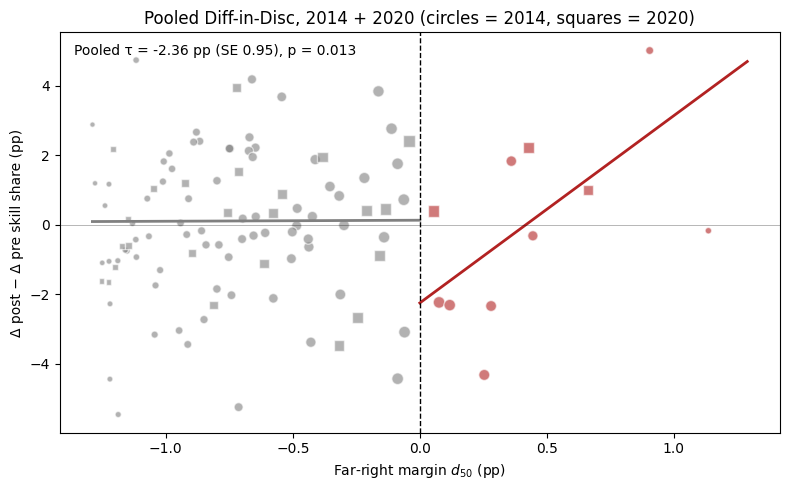

In [15]:
# ── Pooled Diff-in-Disc plot: (post change − pre change) vs. margin, both cycles ──
h = h_pooled
d = df[df['d_50'].abs() <= h].dropna(subset=['delta_skill_share', 'skill_share_trend']).copy()
d['dy'] = (d['delta_skill_share'] - d['skill_share_trend']) * 100                  # difference in changes, pp
d['w'] = 1 - d['d_50'].abs() / h
d['dy'] -= d[d['treat'] == 0].groupby('election_year')['dy'].mean().reindex(d['election_year']).values  # remove cycle level (≈ cycle FE)

fig, ax = plt.subplots(figsize=(8, 5))
for cycle, marker in [(2014, 'o'), (2020, 's')]:                                     # dots by cycle
    for treated, color in [(0, 'grey'), (1, 'firebrick')]:
        s = d[(d['election_year'] == cycle) & (d['treat'] == treated)]
        ax.scatter(s['d_50'], s['dy'], s=15 + 60 * s['w'], marker=marker, color=color, alpha=0.6, edgecolor='white')

for treated, color, grid in [(0, 'grey', np.linspace(-h, 0, 50)), (1, 'firebrick', np.linspace(0, h, 50))]:
    fit = smf.wls('dy ~ d_50', data=d[d['treat'] == treated], weights=d.loc[d['treat'] == treated, 'w']).fit()
    ax.plot(grid, fit.predict(pd.DataFrame({'d_50': grid})), color=color, lw=2)    # local-linear fit per side

est, se, p = (model_pooled_base.params['treat:post'] * 100, model_pooled_base.bse['treat:post'] * 100,
              model_pooled_base.pvalues['treat:post'])
ax.axvline(0, color='black', ls='--', lw=1); ax.axhline(0, color='black', lw=0.5, alpha=0.4)
ax.text(0.02, 0.97, f"Pooled τ = {est:.2f} pp (SE {se:.2f}), p = {p:.3f}", transform=ax.transAxes, va='top')
ax.set_xlabel('Far-right margin $d_{50}$ (pp)'); ax.set_ylabel('Δ post − Δ pre skill share (pp)')
ax.set_title('Pooled Diff-in-Disc, 2014 + 2020 (circles = 2014, squares = 2020)')
plt.tight_layout(); plt.savefig('diffindisc_pooled.pdf', bbox_inches='tight'); plt.show()

Yes, the points really are more important, not just visually. The size is the triangular kernel weight, and exactly the same weights (w) enter the regression. A commune at the cutoff gets weight 1, and one at the edge of the bandwidth gets weight ≈ 0.

- Kink at 2011: 2006, 2011 and 2016 are genuine census years; values in between (2007–2010, 2012–2015) are linearly interpolated, so trends can only change direction at census years

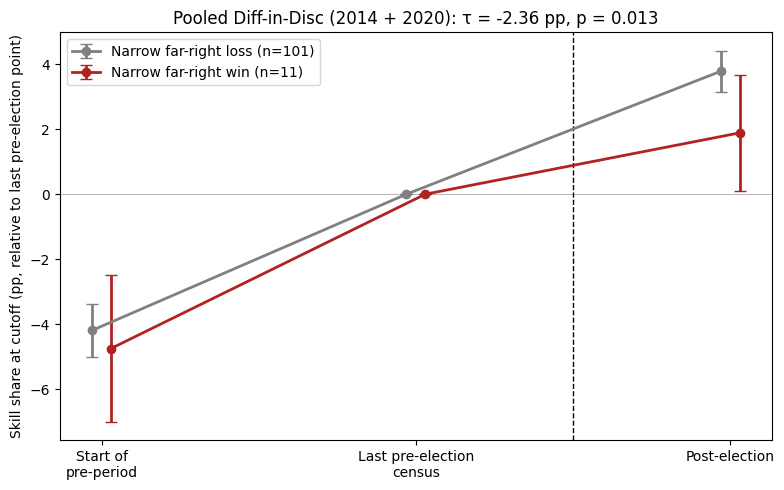

plot-implied τ = -2.453 pp | table = -2.362 pp


In [16]:
# ── Pooled Diff-in-Disc, DiD style: skill share at the cutoff over event time ──
h = h_pooled
d = df[df['d_50'].abs() <= h].dropna(subset=['skill_share_trend', 'delta_skill_share']).copy()
d['w'] = 1 - d['d_50'].abs() / h
# Levels relative to the last pre-election point (= 0), in pp
d['t_m1'] = -d['skill_share_trend'] * 100      # start of pre-period
d['t_0']  = 0.0                                 # last pre-election census (normalization)
d['t_p1'] = d['delta_skill_share'] * 100        # post-election

events = [('t_m1', 'Start of\npre-period'), ('t_0', 'Last pre-election\ncensus'), ('t_p1', 'Post-election')]
fig, ax = plt.subplots(figsize=(8, 5))
paths = {}
for treated, color, name in [(0, 'grey', 'Narrow far-right loss'), (1, 'firebrick', 'Narrow far-right win')]:
    s = d[d['treat'] == treated]
    est, ci = [], []
    for col, _ in events:
        if col == 't_0':
            est.append(0); ci.append(0); continue
        fit = smf.wls(f'{col} ~ d_50', data=s, weights=s['w']).fit(cov_type='HC1')   # value at d_50 = 0
        est.append(fit.params['Intercept']); ci.append(1.96 * fit.bse['Intercept'])
    paths[treated] = est
    x = np.arange(3) + (0.03 if treated else -0.03)                                   # small offset so CIs don't overlap
    ax.errorbar(x, est, yerr=ci, marker='o', color=color, lw=2, capsize=4,
                label=f"{name} (n={s[['code_commune', 'election_year']].drop_duplicates().shape[0]})")

ax.axvline(1.5, color='black', ls='--', lw=1)                                       # election
ax.axhline(0, color='black', lw=0.5, alpha=0.4)
ax.set_xticks(range(3)); ax.set_xticklabels([lab for _, lab in events])
ax.set_ylabel('Skill share at cutoff (pp, relative to last pre-election point)')
tau = model_pooled_base.params['treat:post'] * 100
ax.set_title(f'Pooled Diff-in-Disc (2014 + 2020): τ = {tau:.2f} pp, p = {model_pooled_base.pvalues["treat:post"]:.3f}')
ax.legend(loc='upper left')
plt.tight_layout(); plt.savefig('diffindisc_pooled_did.pdf', bbox_inches='tight'); plt.show()

# Check: plot-implied τ = (gap post) + (gap at start of pre-period); approx. equal to the table (table has cycle FE)
gap = np.array(paths[1]) - np.array(paths[0])
print(f"plot-implied τ = {gap[2] + gap[0]:.3f} pp | table = {tau:.3f} pp")

It's a strong figure, and it tells the story better than the table:

- Before the election, narrow winners were already growing more slowly: about −1.9 → 0 versus −2.8 → 0 for losers, roughly 0.9 pp less.
- After the election they also grow more slowly (+1.5 vs. +2.8, about 1.3 pp less).
- The extra slowdown is only about −0.3 pp, which is your τ, and not significant.

This is exactly why Diff-in-Disc matters. A simple post-election RDD would report about −1.3 pp as an "effect", but most of it existed before the election. That is a nice point for the thesis.

Two notes for the caption:

- The x-axis shows event time, not calendar years. The interval lengths are the same (5 years) only after the window fix above.
- The winner CIs are wide because they rest on 11 communes, so the lines overlap everywhere.